In [8]:
missing_values = df.isnull().sum()

print(missing_values)

Date                             0
Timestamp                        0
Machine_ID                       0
Operation_Mode                   0
Temperature_C                    0
Vibration_Hz                     0
Power_Consumption_kW             0
Network_Latency_ms               0
Packet_Loss_%                    0
Quality_Control_Defect_Rate_%    0
Production_Speed_units_per_hr    0
Predictive_Maintenance_Score     0
Error_Rate_%                     0
Efficiency_Status                0
dtype: int64


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df= pd.read_csv("C:\\Users\\Nishant\\OneDrive\\Documents\\IndusSync\\Data\\Thales_Group_Manufacturing.csv")

In [11]:
numerical_features = df.select_dtypes(include=np.number).drop(
    columns=["Machine_ID"]
)

print("Numerical Features:")
print(numerical_features.columns.tolist())

Numerical Features:
['Temperature_C', 'Vibration_Hz', 'Power_Consumption_kW', 'Network_Latency_ms', 'Packet_Loss_%', 'Quality_Control_Defect_Rate_%', 'Production_Speed_units_per_hr', 'Predictive_Maintenance_Score', 'Error_Rate_%']


In [12]:
categorical_features = df.select_dtypes(include="object")

print("Categorical Features:")
print(categorical_features.columns.tolist())

Categorical Features:
['Operation_Mode', 'Efficiency_Status']


C:\Users\Nishant\AppData\Local\Temp\ipykernel_25204\701796230.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include="object")


In [9]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

C:\Users\Nishant\AppData\Local\Temp\ipykernel_25204\3214812854.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")


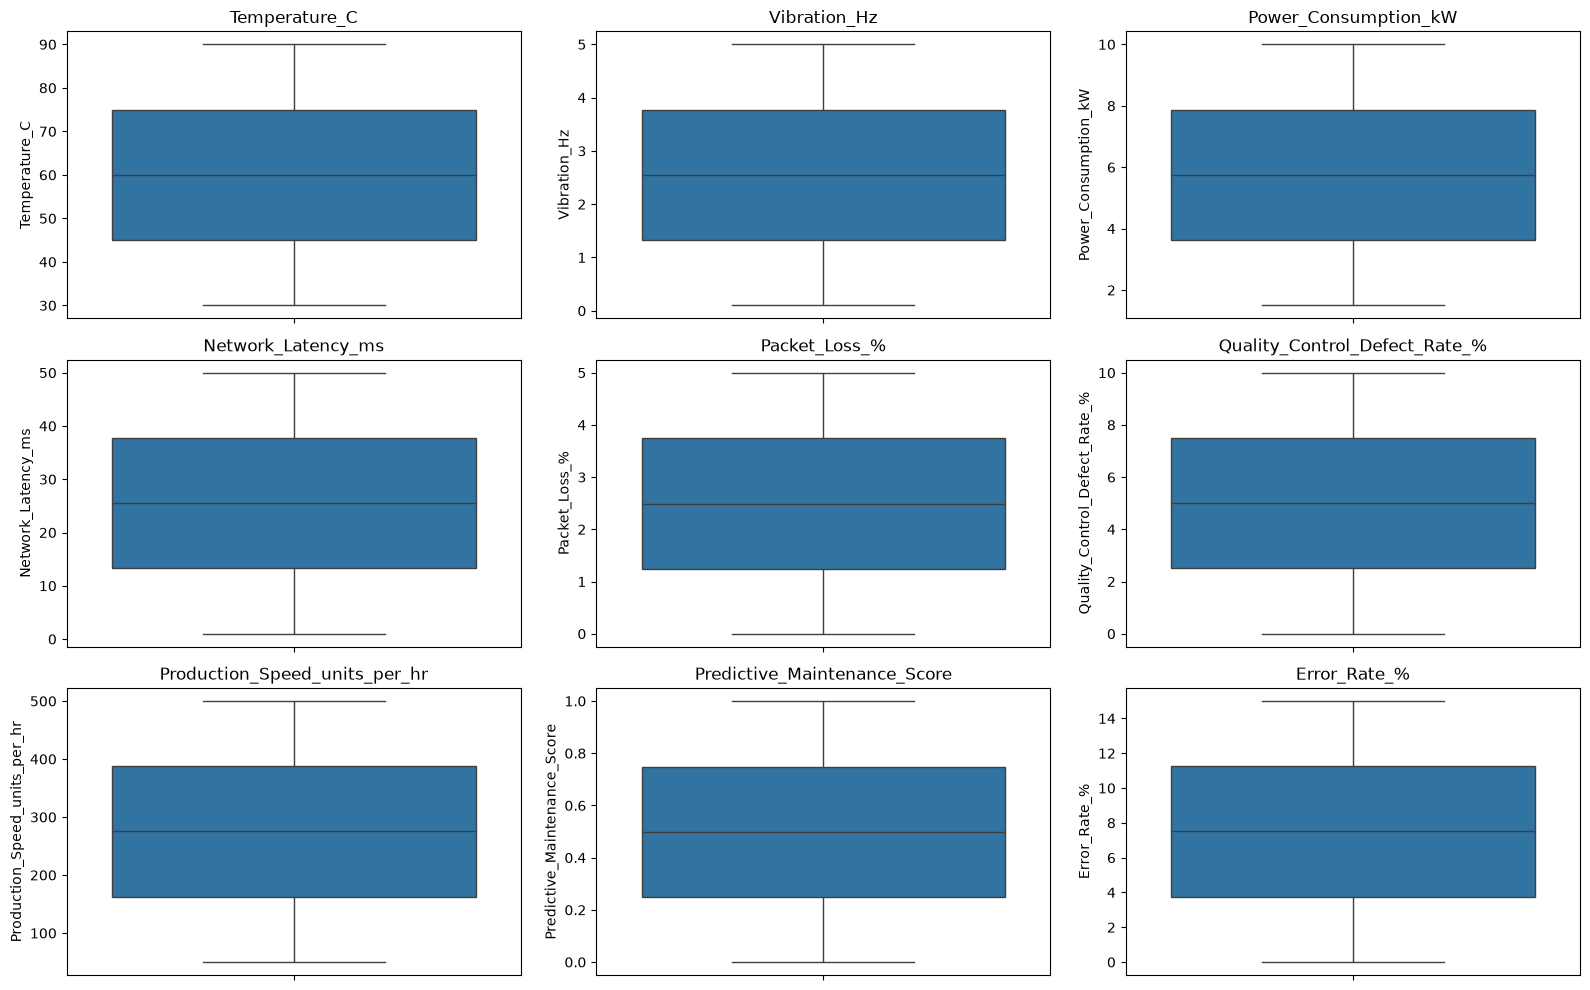

In [13]:
plt.figure(figsize=(16, 10))

for i, column in enumerate(numerical_features.columns, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(y=df[column])

    plt.title(column)

plt.tight_layout()
plt.show()

In [14]:
outlier_results = []

for column in numerical_features.columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    outlier_results.append({
        "Feature": column,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": (len(outliers) / len(df)) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Outlier_Count,Outlier_Percentage
0,Temperature_C,0,0.0
1,Vibration_Hz,0,0.0
2,Power_Consumption_kW,0,0.0
3,Network_Latency_ms,0,0.0
4,Packet_Loss_%,0,0.0
5,Quality_Control_Defect_Rate_%,0,0.0
6,Production_Speed_units_per_hr,0,0.0
7,Predictive_Maintenance_Score,0,0.0
8,Error_Rate_%,0,0.0


In [16]:


class_analysis = df.groupby("Efficiency_Status")[
    numerical_features.columns
].mean().round(3)

display(class_analysis)

,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%
Efficiency_Status,,,,,,,,,
High,60.232,2.548,5.718,25.334,2.528,4.930,450.791,0.495,1.007
Low,60.006,2.550,5.743,25.562,2.494,5.017,254.854,0.500,8.930
Medium,60.154,2.552,5.762,25.566,2.487,4.989,334.125,0.498,2.733


In [17]:
network_features = [
    "Network_Latency_ms",
    "Packet_Loss_%"
]

production_features = [
    "Production_Speed_units_per_hr",
    "Error_Rate_%"
]

correlation_analysis = df[
    network_features + production_features
].corr()

display(correlation_analysis.round(3))

,Network_Latency_ms,Packet_Loss_%,Production_Speed_units_per_hr,Error_Rate_%
Network_Latency_ms,1.000,-0.007,-0.001,0.000
Packet_Loss_%,-0.007,1.000,-0.007,-0.002
Production_Speed_units_per_hr,-0.001,-0.007,1.000,0.006
Error_Rate_%,0.000,-0.002,0.006,1.000


In [18]:
network_features = [
    "Network_Latency_ms",
    "Packet_Loss_%"
]

production_features = [
    "Production_Speed_units_per_hr",
    "Error_Rate_%"
]

selected_features = network_features + production_features

# Pearson correlation
pearson_corr = df[selected_features].corr(method="pearson")

# Spearman correlation
spearman_corr = df[selected_features].corr(method="spearman")

print("PEARSON CORRELATION")
display(pearson_corr.round(3))

print("SPEARMAN CORRELATION")
display(spearman_corr.round(3))

PEARSON CORRELATION


,Network_Latency_ms,Packet_Loss_%,Production_Speed_units_per_hr,Error_Rate_%
Network_Latency_ms,1.000,-0.007,-0.001,0.000
Packet_Loss_%,-0.007,1.000,-0.007,-0.002
Production_Speed_units_per_hr,-0.001,-0.007,1.000,0.006
Error_Rate_%,0.000,-0.002,0.006,1.000


SPEARMAN CORRELATION


,Network_Latency_ms,Packet_Loss_%,Production_Speed_units_per_hr,Error_Rate_%
Network_Latency_ms,1.000,-0.007,-0.001,0.000
Packet_Loss_%,-0.007,1.000,-0.007,-0.002
Production_Speed_units_per_hr,-0.001,-0.007,1.000,0.006
Error_Rate_%,0.000,-0.002,0.006,1.000


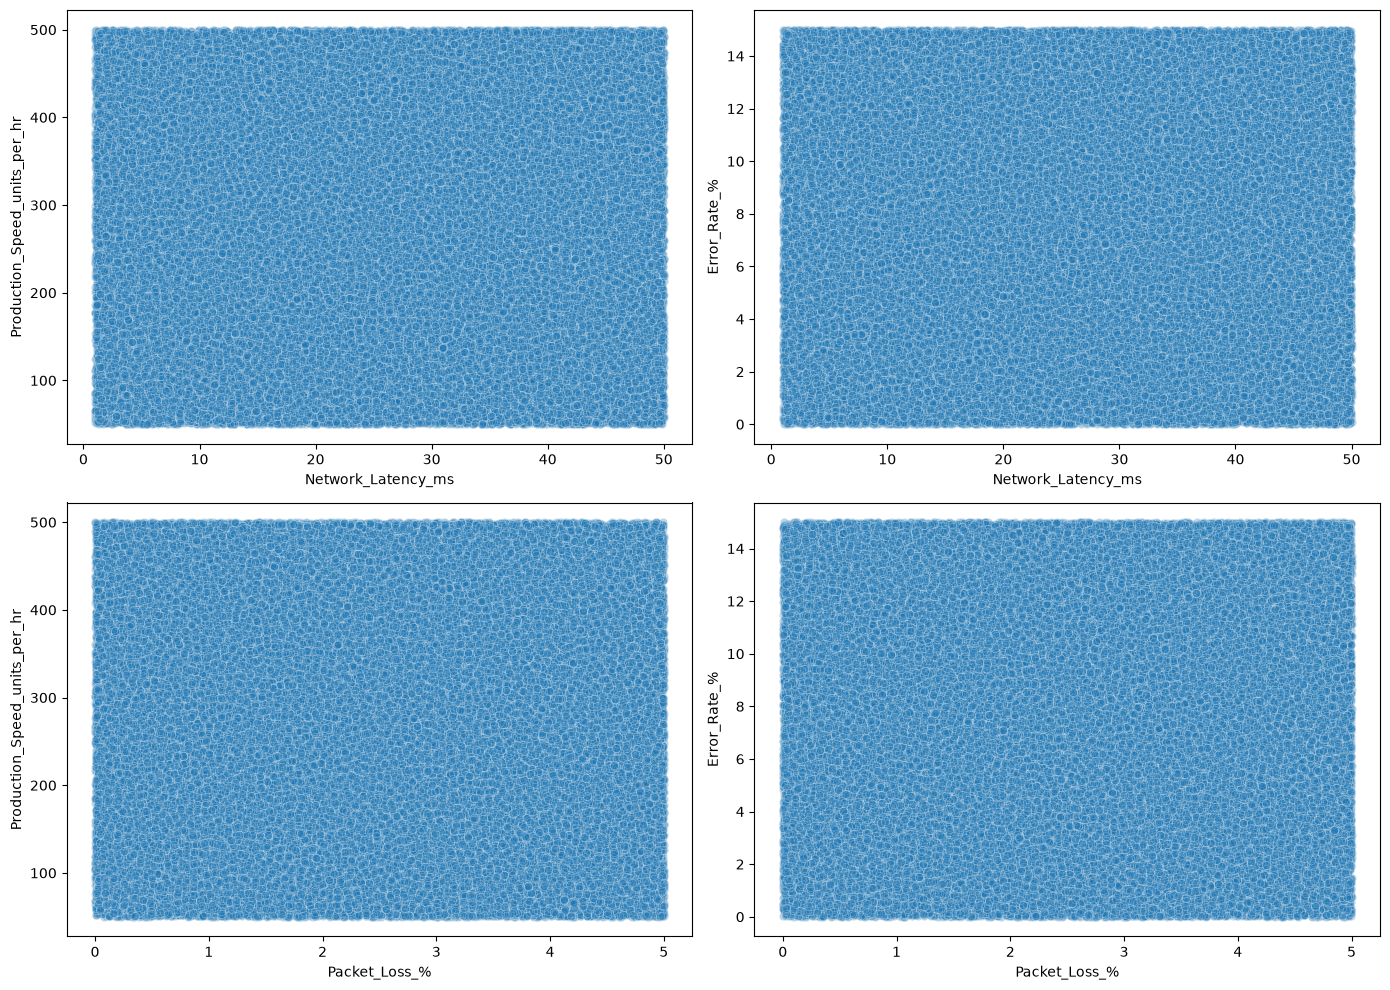

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(
    data=df,
    x="Network_Latency_ms",
    y="Production_Speed_units_per_hr",
    alpha=0.3,
    ax=axes[0, 0]
)

sns.scatterplot(
    data=df,
    x="Network_Latency_ms",
    y="Error_Rate_%",
    alpha=0.3,
    ax=axes[0, 1]
)

sns.scatterplot(
    data=df,
    x="Packet_Loss_%",
    y="Production_Speed_units_per_hr",
    alpha=0.3,
    ax=axes[1, 0]
)

sns.scatterplot(
    data=df,
    x="Packet_Loss_%",
    y="Error_Rate_%",
    alpha=0.3,
    ax=axes[1, 1]
)

plt.tight_layout()
plt.show()

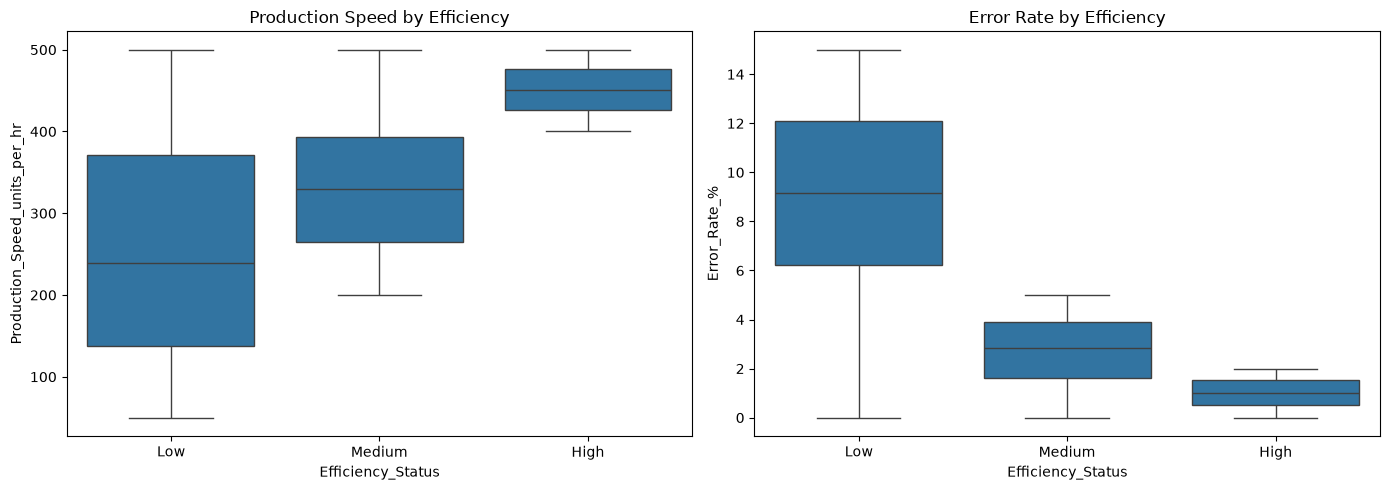

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="Efficiency_Status",
    y="Production_Speed_units_per_hr",
    ax=axes[0]
)

axes[0].set_title("Production Speed by Efficiency")

sns.boxplot(
    data=df,
    x="Efficiency_Status",
    y="Error_Rate_%",
    ax=axes[1]
)

axes[1].set_title("Error Rate by Efficiency")

plt.tight_layout()
plt.show()

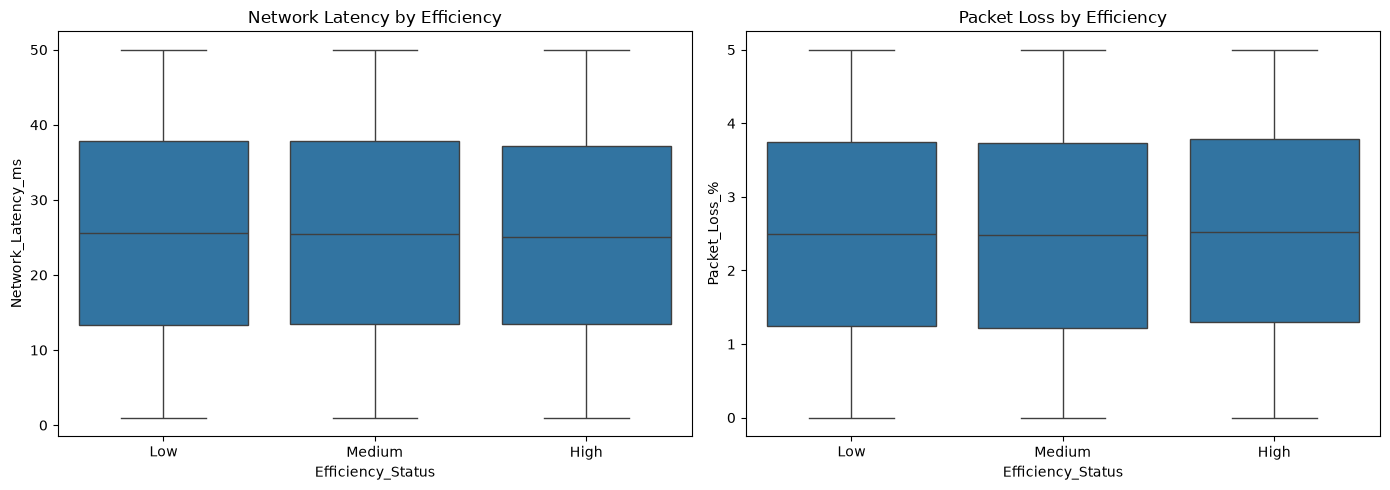

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="Efficiency_Status",
    y="Network_Latency_ms",
    ax=axes[0]
)

sns.boxplot(
    data=df,
    x="Efficiency_Status",
    y="Packet_Loss_%",
    ax=axes[1]
)

axes[0].set_title("Network Latency by Efficiency")
axes[1].set_title("Packet Loss by Efficiency")

plt.tight_layout()
plt.show()